<a href="https://colab.research.google.com/github/rorellana-analytics/data-analytics-portfolio/blob/main/Analisis_Ventas_Globales_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis de Ventas Globales en Python (Proyecto de Portafolio con Datos Ficticios)

> **Nota de origen y transparencia de datos:** Las tablas utilizadas en este análisis (`events.csv`, `products.csv` y `countries.csv`) corresponden a un **conjunto de datos ficticio / simulado desarrollado en el marco de un curso finalizado**, y no a registros comerciales o contables de una empresa real. Los importes elevados y las escalas de las métricas reflejan la estructura del ejercicio de práctica y no deben interpretarse como estados financieros auditados.

### Enfoque y propósito del proyecto
* **Objetivo técnico:** Demostrar un flujo de trabajo reproducible en Python (`pandas`, `NumPy`, `Matplotlib`, `Seaborn`) para limpieza de datos, cruce relacional, cálculo de indicadores, análisis de Pareto / ABC, revisión logística / estadística y análisis temporal.
* **Criterios y casos borde resueltos:**
  * Conservación del código ISO alpha-2 `'NA'` de Namibia (`keep_default_na=False`) para evitar que se interprete como valor nulo.
  * Normalización de inconsistencias de texto y caracteres homógrafos cirílicos visuales hacia caracteres latinos.
  * Tratamiento de 82 registros (6.17 %) sin `Country Code` mediante la etiqueta `'Unknown'` en el consolidado global y su exclusión en los cortes geográficos (`df_geo`).
  * Imputación de 2 valores faltantes (0.15 %) en `Units Sold` mediante la mediana de su respectivo `Product ID`, manteniendo **1,330 pedidos** en Python frente a los **1,328 pedidos** sin vacíos obtenidos en la depuración de hojas de cálculo.
  * Evaluación estadística y operativa de los días de envío frente al beneficio neto (correlación lineal baja `r ≈ 0.0607`, alta dispersión y presencia de factores operativos no observados en el *dataset*).

## Estructura del Cuaderno (`Analisis_Ventas_Globales_Python.ipynb`)


1. **Portada y alcance metodológico:** Declaración de datos ficticios / de curso, objetivos, trazabilidad frente a hojas de cálculo (1,330 vs. 1,328 pedidos) y reglas de limpieza.
2. **Carga portátil y depuración inicial:** Lectura flexible entre entorno local y Google Drive, preservación del código `'NA'` de Namibia, limpieza de cadenas y homógrafos, cálculo de `shipping_days` e imputación de nulos en `Units Sold`.
3. **Consolidación relacional y KPIs globales:** Cruce (`left join`) con `products` y `countries`, asignación de `'Unknown'` en ubicaciones faltantes y cálculo de métricas globales de ingresos, costos, beneficio, margen y ticket promedio.
4. **Análisis por categoría y curva Pareto / ABC:** Desempeño de ingresos, beneficio y unidades por categoría, manteniendo los gráficos originales y sumando la clasificación ABC / Pareto.
5. **Geografía, canales de venta y logística:** Análisis de regiones (`df_geo`), Top 10 países por pedidos y por beneficio, equilibrio `Online` / `Offline`, dispersión de `shipping_days` y análisis de correlación (`r ≈ 0.0607`) con prioridad de pedido.
6. **Dinámica temporal, estacionalidad y cuadre numérico:** Evolución anual, ingresos por día de la semana, mapa de calor mensual por categoría y tablas de verificación de cifras.
7. **Informe ejecutivo, limitaciones del dataset ficticio y próximos pasos:** Síntesis de hallazgos, límites metodológicos por tratarse de datos simulados y criterios de mejora.

In [12]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from IPython.display import display
except ImportError:
    display = print

# Configuración visual profesional para todo el informe
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (11, 5)

# 1. Carga portátil: prioriza carpeta local/GitHub ('Data/') y recurre a Google Drive en Colab
if os.path.exists("Data/events.csv"):
    ruta_base = "Data/"
else:
    from google.colab import drive
    drive.mount('/content/drive')
    ruta_base = '/content/drive/MyDrive/Final_project/'

# keep_default_na=False evita que el código ISO-2 'NA' (Namibia) se lea como NaN por defecto;
# luego convertimos cadenas vacías '' en np.nan para detectar faltantes reales.
events = pd.read_csv(f'{ruta_base}events.csv')
products = pd.read_csv(f'{ruta_base}products.csv')
countries = pd.read_csv(f'{ruta_base}countries.csv', keep_default_na=False)
countries = countries.replace({'': np.nan})

# 2. Inspección general de cada tabla
for nombre, tabla in [('EVENTS', events), ('PRODUCTS', products), ('COUNTRIES', countries)]:
    print(f"{'='*50}\nTABLA: {nombre} | Dimensiones: {tabla.shape}\n{'='*50}")
    print(tabla.info())
    display(tabla.head(3))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TABLA: EVENTS | Dimensiones: (1330, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1330 entries, 0 to 1329
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order ID        1330 non-null   int64  
 1   Order Date      1330 non-null   object 
 2   Ship Date       1330 non-null   object 
 3   Order Priority  1330 non-null   object 
 4   Country Code    1248 non-null   object 
 5   Product ID      1330 non-null   int64  
 6   Sales Channel   1330 non-null   object 
 7   Units Sold      1328 non-null   float64
 8   Unit Price      1330 non-null   float64
 9   Unit Cost       1330 non-null   float64
dtypes: float64(3), int64(2), object(5)
memory usage: 104.0+ KB
None


,Order ID,Order Date,Ship Date,Order Priority,Country Code,Product ID,Sales Channel,Units Sold,Unit Price,Unit Cost
0,100640618,10/8/2014,10/18/2014,M,NOR,2103,Online,650.0,205.70,117.11
1,100983083,8/11/2016,8/11/2016,C,SRB,2103,Offline,1993.0,205.70,117.11
2,101025998,7/18/2014,8/11/2014,M,NaN,7940,Online,4693.0,668.27,502.54


TABLA: PRODUCTS | Dimensiones: (12, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         12 non-null     int64 
 1   item_type  12 non-null     object
dtypes: int64(1), object(1)
memory usage: 324.0+ bytes
None


,id,item_type
0,2103,Cereal
1,7940,Household
2,2455,Clothes


TABLA: COUNTRIES | Dimensiones: (249, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 249 entries, 0 to 248
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   name        249 non-null    object
 1   alpha-2     249 non-null    object
 2   alpha-3     249 non-null    object
 3   region      248 non-null    object
 4   sub-region  248 non-null    object
dtypes: object(5)
memory usage: 9.9+ KB
None


,name,alpha-2,alpha-3,region,sub-region
0,Afghanistan,AF,AFG,Asia,Southern Asia
1,Åland Islands,AX,ALA,Europe,Northern Europe
2,Albania,AL,ALB,Europe,Southern Europe


## **Etapa 1: Descripción General de los Datos**

- **`events.csv`** *(tabla de hechos / transaccional)*: registra las operaciones de venta a lo largo de varios años, incluyendo `Order ID`, fechas de pedido y envío (`Order Date`, `Ship Date`), prioridad (`Order Priority`), canal de venta (`Sales Channel`), unidades vendidas (`Units Sold`), precios y costos unitarios (`Unit Price`, `Unit Cost`) y claves de referencia (`Country Code`, `Product ID`).
- **`products.csv`** *(tabla dimensional de catálogo)*: asocia cada identificador de producto (`id`) con su categoría (`item_type`).
- **`countries.csv`** *(tabla dimensional geográfica)*: asocia los códigos y nombres de territorio (`name`, `alpha-2`, `alpha-3`) con su clasificación regional (`region`, `sub-region`). Se lee con `keep_default_na=False` para evitar que el código ISO-2 `"NA"` (Namibia) sea interpretado por defecto como valor nulo.

- **Llaves de conexión (Claves primarias y foráneas):**
  - `events.Product ID` *(FK)* $\rightarrow$ `products.id` *(PK)* para incorporar `item_type`.
  - `events.Country Code` *(FK)* $\rightarrow$ `countries.alpha-3` *(clave de cruce en el cuaderno)* para incorporar `name`, `region` y `sub-region`.

> **Criterio de trabajo en este cuaderno:** Se conservan los **1.330 pedidos** de `events.csv` (los 2 valores faltantes en `Units Sold` se imputan en la etapa de limpieza mediante la mediana de su `Product ID`). Si comparas este cuaderno con una versión en hojas de cálculo donde se eliminaron filas incompletas (1.328 pedidos), los totales agregados tendrán una leve diferencia explicada por este criterio.

In [13]:
import re

# --- 2.1 AUDITORÍA DE VALORES FALTANTES ---
for nombre, tabla in [('events', events), ('products', products), ('countries', countries)]:
    nulos = tabla.isna().sum()
    pct_nulos = (nulos / len(tabla) * 100).round(2)
    resumen_nulos = pd.DataFrame({'Nulos': nulos, 'Porcentaje (%)': pct_nulos})
    print(f"\n--- Valores faltantes en {nombre} ---")
    nulos_activos = resumen_nulos[resumen_nulos['Nulos'] > 0]
    if len(nulos_activos) > 0:
        print(nulos_activos)
    else:
        print("Sin valores nulos.")

# Verificación puntual del código ISO-2 de Namibia ('NA') tras keep_default_na=False
namibia_row = countries.loc[countries['name'].astype(str).str.contains('Namibia', case=False, na=False), ['name', 'alpha-2', 'alpha-3']]
print("\n--- Verificación código ISO de Namibia ---")
print(namibia_row)

# --- 2.2 DETECCIÓN DE CARACTERES NO ASCII Y ESPACIOS EXTRA ---
# Nota: caracteres fuera de ASCII incluyen tildes/diacríticos válidos (ej. 'Curaçao', 'Réunion')
# y posibles homógrafos cirílicos que se normalizarán en la etapa de limpieza.
def auditar_texto(df_in, nombre_tabla):
    print(f"\n--- Revisión de caracteres no ASCII y espacios extra en {nombre_tabla} ---")
    for col in df_in.select_dtypes(include='object').columns:
        serie = df_in[col].dropna().astype(str)
        raros = serie[serie.apply(lambda x: bool(re.search(r'[^\x00-\x7F]', x)))]
        espacios_raros = serie[serie.apply(lambda x: x != x.strip() or bool(re.search(r'\s{2,}', x)))]
        if len(raros) > 0:
            print(f"Columna '{col}' -> {len(raros)} valores no ASCII. Ejemplos: {raros.unique()[:5]}")
        if len(espacios_raros) > 0:
            print(f"Columna '{col}' -> {len(espacios_raros)} valores con espacios extra. Ejemplos: {espacios_raros.unique()[:5]}")

for nombre, tabla in [('events', events), ('products', products), ('countries', countries)]:
    auditar_texto(tabla, nombre)


--- Valores faltantes en events ---
              Nulos  Porcentaje (%)
Country Code     82            6.17
Units Sold        2            0.15

--- Valores faltantes en products ---
Sin valores nulos.

--- Valores faltantes en countries ---
            Nulos  Porcentaje (%)
region          1             0.4
sub-region      1             0.4

--- Verificación código ISO de Namibia ---
        name alpha-2 alpha-3
153  Namibia      NA     NAM

--- Revisión de caracteres no ASCII y espacios extra en events ---
Columna 'Order Priority' -> 3 valores con espacios extra. Ejemplos: [' C' 'M ']

--- Revisión de caracteres no ASCII y espacios extra en products ---

--- Revisión de caracteres no ASCII y espacios extra en countries ---
Columna 'name' -> 5 valores no ASCII. Ejemplos: ['Åland Islands' "Côte d'Ivoire" 'Curaçao' 'Réunion' 'Saint Barthélemy']


In [14]:
# Mapa de traducción de caracteres cirílicos homógrafos visuales a latinos
cirilico_a_latino = str.maketrans({
    'А': 'A', 'В': 'B', 'С': 'C', 'Е': 'E', 'Н': 'H', 'І': 'I', 'К': 'K',
    'М': 'M', 'О': 'O', 'Р': 'P', 'Т': 'T', 'Х': 'X',
    'а': 'a', 'с': 'c', 'е': 'e', 'і': 'i', 'о': 'o', 'р': 'p', 'х': 'x', 'у': 'y'
})

def limpiar_texto(df_in):
    df_clean = df_in.copy()
    for col in df_clean.select_dtypes(include='object').columns:
        # Solo limpiamos valores no nulos para preservar nulos reales y no alterar 'NA' (Namibia)
        mask_no_nulo = df_clean[col].notna()
        df_clean.loc[mask_no_nulo, col] = (
            df_clean.loc[mask_no_nulo, col]
            .astype(str)
            .str.strip()
            .str.replace(r'\s+', ' ', regex=True)
            .apply(lambda s: s.translate(cirilico_a_latino))
        )
        # Cadenas vacías o con solo espacios pasan a NaN ('NA' de Namibia se conserva intacto)
        df_clean.loc[mask_no_nulo & (df_clean[col] == ''), col] = np.nan
    return df_clean

events = limpiar_texto(events)
products = limpiar_texto(products)
countries = limpiar_texto(countries)

# Revisión de duplicados exactos tras normalizar texto
dup_events = events.duplicated().sum()
dup_products = products.duplicated().sum()
dup_countries = countries.duplicated().sum()

print(f"Duplicados en events: {dup_events}")
print(f"Duplicados en products: {dup_products}")
print(f"Duplicados en countries: {dup_countries}")

# Eliminar duplicados si existen
if dup_events > 0:
    events = events.drop_duplicates().copy()
if dup_products > 0:
    products = products.drop_duplicates().copy()
if dup_countries > 0:
    countries = countries.drop_duplicates().copy()

Duplicados en events: 0
Duplicados en products: 0
Duplicados en countries: 0


In [15]:
# 1. Revisar valores únicos de columnas categóricas y códigos en events y products
print("--- Valores únicos en Sales Channel ---")
print(events['Sales Channel'].value_counts(dropna=False))

print("\n--- Valores únicos en Order Priority ---")
print(events['Order Priority'].value_counts(dropna=False))

print("\n--- Muestra de Country Code en events ---")
print("Ejemplos:", events['Country Code'].dropna().unique()[:15])
print("Longitud de códigos:", events['Country Code'].dropna().astype(str).str.len().value_counts())

print("\n--- Tabla PRODUCTS completa ---")
display(products)

# 2. Revisar Order ID duplicados y filas con nulos o faltantes clave
print("\n--- Order ID duplicados en events ---")
print("Order ID duplicados:", events['Order ID'].duplicated().sum())

print("\n--- Filas con nulos en countries (verificando que 'NA' de Namibia no figure como nulo) ---")
display(countries[countries.isna().any(axis=1)])

print("\n--- Filas con Units Sold nulo en events (se imputarán por mediana de producto para conservar 1.330 pedidos) ---")
display(events[events['Units Sold'].isna()])

# 3. Conversión de tipos numéricos/fechas y detección de anomalías
for col in ['Units Sold', 'Unit Price', 'Unit Cost']:
    events[col] = pd.to_numeric(events[col], errors='coerce')

events['Order Date'] = pd.to_datetime(events['Order Date'], errors='coerce')
events['Ship Date'] = pd.to_datetime(events['Ship Date'], errors='coerce')
events['shipping_days'] = (events['Ship Date'] - events['Order Date']).dt.days

print("\n--- Estadísticas numéricas y días de envío ---")
display(events[['Units Sold', 'Unit Price', 'Unit Cost', 'shipping_days']].describe())

print("Fechas de envío anteriores al pedido (shipping_days < 0):", (events['shipping_days'] < 0).sum())
print("Casos donde Unit Cost > Unit Price:", (events['Unit Cost'] > events['Unit Price']).sum())

--- Valores únicos en Sales Channel ---
Sales Channel
Offline    667
Online     660
online       3
Name: count, dtype: int64

--- Valores únicos en Order Priority ---
Order Priority
M    354
H    335
L    334
C    307
Name: count, dtype: int64

--- Muestra de Country Code en events ---
Ejemplos: ['NOR' 'SRB' 'MNE' 'SVK' 'FRA' 'ESP' 'HRV' 'DEU' 'ARM' 'GEO' 'GBR' 'SVN'
 'ROU' 'POL' 'LUX']
Longitud de códigos: Country Code
3    1248
Name: count, dtype: int64

--- Tabla PRODUCTS completa ---


,id,item_type
0,2103,Cereal
1,7940,Household
2,2455,Clothes
3,1270,Beverages
4,8681,Office Supplies
5,4594,Fruits
6,5988,Vegetables
7,7331,Baby Food
8,8875,Meat
9,8293,Cosmetics



--- Order ID duplicados en events ---
Order ID duplicados: 0

--- Filas con nulos en countries (verificando que 'NA' de Namibia no figure como nulo) ---


,name,alpha-2,alpha-3,region,sub-region
8,Antarctica,AQ,ATA,NaN,NaN



--- Filas con Units Sold nulo en events (se imputarán por mediana de producto para conservar 1.330 pedidos) ---


,Order ID,Order Date,Ship Date,Order Priority,Country Code,Product ID,Sales Channel,Units Sold,Unit Price,Unit Cost
183,217165648,5/20/2014,6/8/2014,M,ESP,8875,Offline,NaN,421.89,364.69
319,309655511,5/5/2014,5/21/2014,C,HRV,3127,Offline,NaN,81.73,56.67



--- Estadísticas numéricas y días de envío ---


,Units Sold,Unit Price,Unit Cost,shipping_days
count,1328.000000,1330.000000,1330.000000,1330.000000
mean,4952.201807,264.893541,187.246812,24.775940
std,2905.198996,217.323460,176.158873,14.577915
min,2.000000,9.330000,6.920000,0.000000
25%,2356.750000,81.730000,35.840000,12.000000
50%,4962.000000,154.060000,97.440000,25.000000
75%,7459.500000,437.200000,263.330000,37.000000
max,9999.000000,668.270000,524.960000,50.000000


Fechas de envío anteriores al pedido (shipping_days < 0): 0
Casos donde Unit Cost > Unit Price: 0


In [16]:
# ==============================================================================
# ETAPA 2: LIMPIEZA Y ESTANDARIZACIÓN DEFINITIVA
# ==============================================================================

# 1. Estandarizar 'Sales Channel' ('online' -> 'Online') y limpiar textos
events['Sales Channel'] = events['Sales Channel'].str.strip().str.capitalize()
events['Order Priority'] = events['Order Priority'].str.strip().str.upper()
events['Country Code'] = events['Country Code'].str.strip().str.upper()

# 2. Asegurar código ISO alpha-2 de Namibia ('NA') en countries (protegido desde la carga con keep_default_na=False)
countries.loc[countries['name'] == 'Namibia', 'alpha-2'] = 'NA'

# 3. Convertir fechas a datetime y calcular días de envío
events['Order Date'] = pd.to_datetime(events['Order Date'])
events['Ship Date'] = pd.to_datetime(events['Ship Date'])
events['shipping_days'] = (events['Ship Date'] - events['Order Date']).dt.days

# 4. Imputar los 2 valores faltantes de 'Units Sold' con la mediana de su mismo Product ID
# (Conserva los 1,330 pedidos; en la hoja de cálculo depurada sin vacíos se reportan 1,328 pedidos)
mediana_por_producto = events.groupby('Product ID')['Units Sold'].transform('median')
events['Units Sold'] = events['Units Sold'].fillna(mediana_por_producto).round().astype(int)

# ==============================================================================
# ETAPA 3.1: COMBINACIÓN DE TABLAS (MERGE) Y CREACIÓN DE MÉTRICAS FINANCIERAS
# ==============================================================================

df = (
    events
    .merge(products, left_on='Product ID', right_on='id', how='left')
    .merge(
        countries[['name', 'alpha-2', 'alpha-3', 'region', 'sub-region']],
        left_on='Country Code',
        right_on='alpha-3',
        how='left'
    )
)

# Etiquetar los 82 pedidos sin país como 'Unknown' para conservarlos en métricas globales
df['country'] = df['name'].fillna('Unknown')
df['region'] = df['region'].fillna('Unknown')
df['sub-region'] = df['sub-region'].fillna('Unknown')

# Eliminar columnas redundantes y renombrar para mayor claridad
df = df.drop(columns=['id', 'alpha-3', 'name']).rename(columns={
    'item_type': 'product_category',
    'alpha-2': 'country_iso2',
    'Sales Channel': 'sales_channel',
    'Order Priority': 'order_priority',
    'Order Date': 'order_date',
    'Ship Date': 'ship_date',
    'Units Sold': 'units_sold',
    'Unit Price': 'unit_price',
    'Unit Cost': 'unit_cost'
})

# Calcular métricas financieras y temporales
df['revenue'] = df['units_sold'] * df['unit_price']
df['cost'] = df['units_sold'] * df['unit_cost']
df['profit'] = df['revenue'] - df['cost']
df['profit_margin_pct'] = np.where(
    df['revenue'] != 0,
    (df['profit'] / df['revenue']) * 100,
    np.nan
)
df['order_year'] = df['order_date'].dt.year
df['order_month'] = df['order_date'].dt.month
df['day_of_week'] = df['order_date'].dt.day_name()

# ==============================================================================
# ETAPA 3.2: INDICADORES CLAVE DE RENDIMIENTO (KPIs GLOBALES)
# ==============================================================================
total_pedidos = df['Order ID'].nunique()
total_unidades = df['units_sold'].sum()
ingresos_totales = df['revenue'].sum()
costos_totales = df['cost'].sum()
beneficio_total = df['profit'].sum()
margen_global = (beneficio_total / ingresos_totales) * 100
ticket_promedio = df['revenue'].mean()
paises_cubiertos = df[df['country'] != 'Unknown']['country'].nunique()
regiones_cubiertas = df[df['region'] != 'Unknown']['region'].nunique()
tiempo_envio_prom = df['shipping_days'].mean()

print("=" * 55)
print("RESUMEN EJECUTIVO DE KPIs GLOBALES")
print("=" * 55)
print(f"Total de pedidos:              {total_pedidos:,}")
print(f"Total de unidades vendidas:    {total_unidades:,}")
print(f"Ingresos totales (Revenue):    ${ingresos_totales:,.2f}")
print(f"Costos totales (Cost):         ${costos_totales:,.2f}")
print(f"Beneficio neto total (Profit): ${beneficio_total:,.2f}")
print(f"Margen de beneficio global:    {margen_global:.2f}%")
print(f"Ingreso promedio por pedido:   ${ticket_promedio:,.2f}")
print(f"Países cubiertos:              {paises_cubiertos} (en {regiones_cubiertas} regiones)")
print(f"Tiempo promedio de envío:      {tiempo_envio_prom:.2f} días")
print("=" * 55)

RESUMEN EJECUTIVO DE KPIs GLOBALES
Total de pedidos:              1,330
Total de unidades vendidas:    6,586,062
Ingresos totales (Revenue):    $1,704,556,683.99
Costos totales (Cost):         $1,202,727,516.55
Beneficio neto total (Profit): $501,829,167.44
Margen de beneficio global:    29.44%
Ingreso promedio por pedido:   $1,281,621.57
Países cubiertos:              45 (en 2 regiones)
Tiempo promedio de envío:      24.78 días


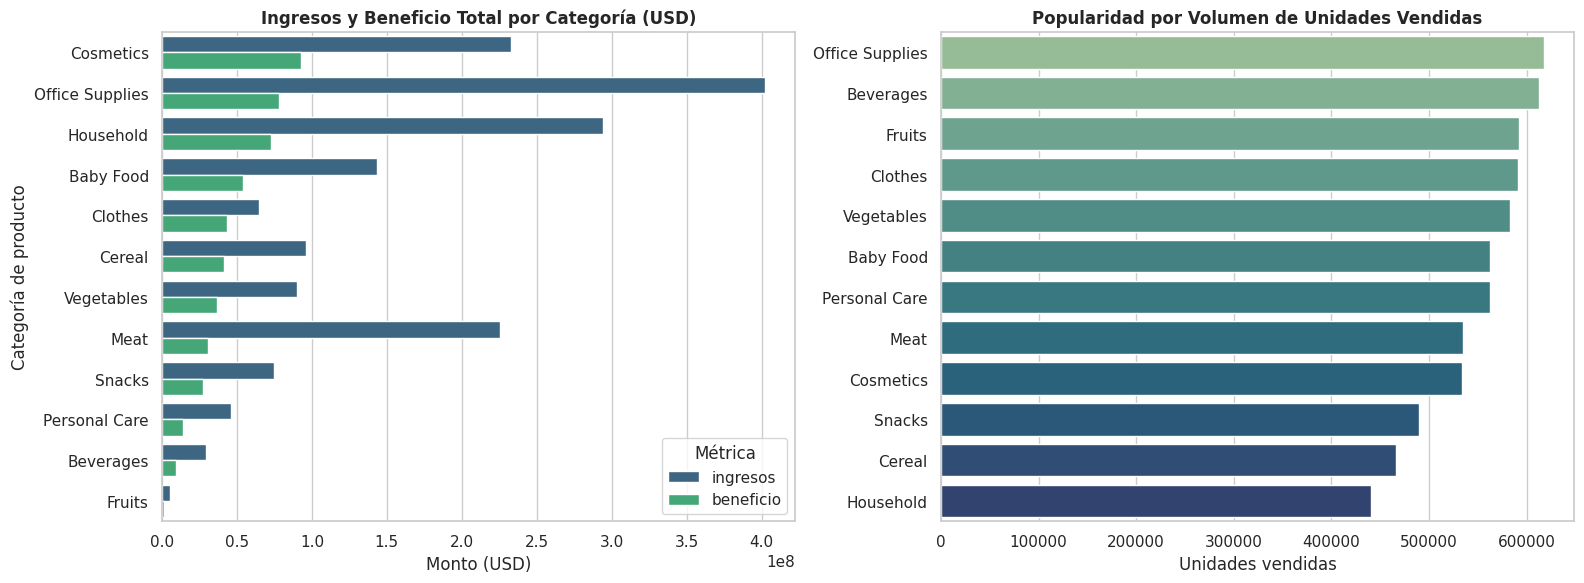

,product_category,pedidos,unidades,ingresos,costos,beneficio,margen_pct
0,Cosmetics,114,533291,2.331548e+08,1.404315e+08,92723306.17,39.77
1,Office Supplies,123,617641,4.022140e+08,3.242368e+08,77977176.25,19.39
2,Household,97,440249,2.942052e+08,2.212427e+08,72962466.77,24.80
3,Baby Food,112,562706,1.436476e+08,8.970659e+07,53940997.16,37.55
4,Clothes,105,591385,6.462655e+07,2.119524e+07,43431314.40,67.20
5,Cereal,103,465685,9.579140e+07,5.453637e+07,41255034.15,43.07
6,Vegetables,114,582544,8.974673e+07,5.297073e+07,36776002.72,40.98
7,Meat,111,535224,2.258057e+08,1.951908e+08,30614812.80,13.56
8,Snacks,103,490160,7.478861e+07,4.776119e+07,27027422.40,36.14
9,Personal Care,115,562372,4.596266e+07,3.186962e+07,14093042.32,30.66


,product_category,ingresos,beneficio,margen_pct,pct_beneficio,pct_acumulado,clase_ABC
0,Cosmetics,2.331548e+08,92723306.17,39.77,18.48,18.48,A
1,Office Supplies,4.022140e+08,77977176.25,19.39,15.54,34.02,A
2,Household,2.942052e+08,72962466.77,24.80,14.54,48.55,A
3,Baby Food,1.436476e+08,53940997.16,37.55,10.75,59.30,A
4,Clothes,6.462655e+07,43431314.40,67.20,8.65,67.96,A
5,Cereal,9.579140e+07,41255034.15,43.07,8.22,76.18,A
6,Vegetables,8.974673e+07,36776002.72,40.98,7.33,83.51,A
7,Meat,2.258057e+08,30614812.80,13.56,6.10,89.61,B
8,Snacks,7.478861e+07,27027422.40,36.14,5.39,94.99,B
9,Personal Care,4.596266e+07,14093042.32,30.66,2.81,97.80,B


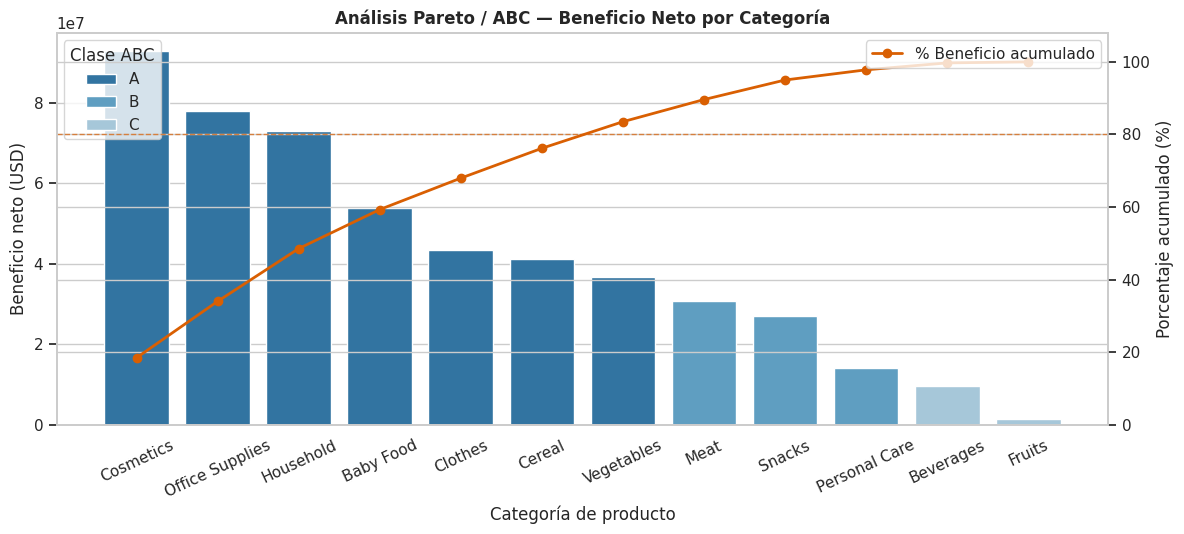

In [17]:
# ==============================================================================
# 1. RESUMEN FINANCIERO Y DE VOLUMEN POR CATEGORÍA DE PRODUCTO
# ==============================================================================
cat_summary = (
    df.groupby('product_category', as_index=False)
    .agg(
        pedidos=('Order ID', 'nunique'),
        unidades=('units_sold', 'sum'),
        ingresos=('revenue', 'sum'),
        costos=('cost', 'sum'),
        beneficio=('profit', 'sum')
    )
    .sort_values(by='beneficio', ascending=False)
    .reset_index(drop=True)
)

cat_summary['margen_pct'] = np.where(
    cat_summary['ingresos'] != 0,
    (cat_summary['beneficio'] / cat_summary['ingresos']) * 100,
    np.nan
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel izquierdo: Ingresos vs Beneficio por categoría
cat_melted = cat_summary.melt(
    id_vars='product_category',
    value_vars=['ingresos', 'beneficio'],
    var_name='Métrica',
    value_name='USD'
)
sns.barplot(
    data=cat_melted,
    y='product_category',
    x='USD',
    hue='Métrica',
    order=cat_summary['product_category'],
    ax=axes[0],
    palette='viridis'
)
axes[0].set_title('Ingresos y Beneficio Total por Categoría (USD)', fontweight='bold')
axes[0].set_xlabel('Monto (USD)')
axes[0].set_ylabel('Categoría de producto')

# Panel derecho: Popularidad (Unidades vendidas por categoría)
cat_units = cat_summary.sort_values(by='unidades', ascending=False)
sns.barplot(
    data=cat_units,
    y='product_category',
    x='unidades',
    order=cat_units['product_category'],
    hue='product_category',
    palette='crest',
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Popularidad por Volumen de Unidades Vendidas', fontweight='bold')
axes[1].set_xlabel('Unidades vendidas')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()
display(cat_summary.round(2))

# ==============================================================================
# 2. ANÁLISIS ABC / PARETO POR BENEFICIO NETO
# ==============================================================================
pareto_cat = (
    cat_summary[['product_category', 'ingresos', 'beneficio', 'margen_pct']]
    .copy()
    .sort_values(by='beneficio', ascending=False)
    .reset_index(drop=True)
)

total_beneficio_cat = pareto_cat['beneficio'].sum()
pareto_cat['pct_beneficio'] = (pareto_cat['beneficio'] / total_beneficio_cat) * 100
pareto_cat['pct_acumulado'] = pareto_cat['pct_beneficio'].cumsum()

def clasificar_abc(pct_acum_previo):
    if pct_acum_previo <= 80:
        return 'A'
    elif pct_acum_previo <= 95:
        return 'B'
    else:
        return 'C'

pct_acum_previo = pareto_cat['pct_acumulado'].shift(1).fillna(0)
pareto_cat['clase_ABC'] = pct_acum_previo.apply(clasificar_abc)

display(pareto_cat.round(2))

fig, ax1 = plt.subplots(figsize=(12, 5.5))

sns.barplot(
    data=pareto_cat,
    x='product_category',
    y='beneficio',
    hue='clase_ABC',
    dodge=False,
    palette={'A': '#1f77b4', 'B': '#4fa3d1', 'C': '#9ecae1'},
    ax=ax1
)
ax1.set_title('Análisis Pareto / ABC — Beneficio Neto por Categoría', fontweight='bold')
ax1.set_xlabel('Categoría de producto')
ax1.set_ylabel('Beneficio neto (USD)')
ax1.tick_params(axis='x', rotation=25)
ax1.legend(title='Clase ABC', loc='upper left')

ax2 = ax1.twinx()
ax2.plot(
    range(len(pareto_cat)),
    pareto_cat['pct_acumulado'],
    color='#d95f02',
    marker='o',
    linewidth=2,
    label='% Beneficio acumulado'
)
ax2.axhline(80, color='#d95f02', linestyle='--', linewidth=1, alpha=0.7)
ax2.set_ylabel('Porcentaje acumulado (%)')
ax2.set_ylim(0, 108)
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

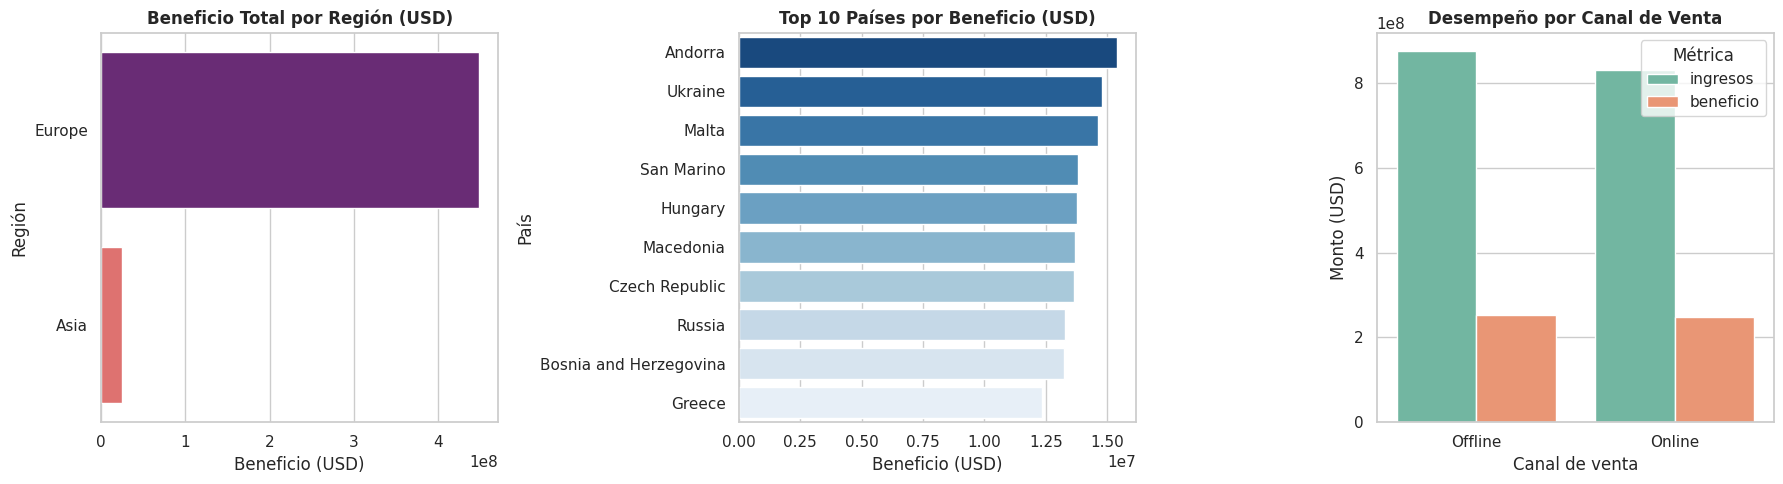

Registros en df_geo (con país conocido): 1248 de 1330 pedidos totales.

--- Resumen por Región (Beneficio USD) ---


,region,profit
1,Europe,4.489515e+08
0,Asia,2.515225e+07



--- Top 10 Países (Beneficio USD) ---


,country,profit
1,Andorra,15410036.63
43,Ukraine,14804925.74
27,Malta,14610127.88
36,San Marino,13792992.81
18,Hungary,13786231.03
26,Macedonia,13684099.95
10,Czech Republic,13635593.78
35,Russia,13267682.64
6,Bosnia and Herzegovina,13257602.77
17,Greece,12324450.13



--- Resumen por Canal de Venta ---


,sales_channel,ingresos,beneficio
0,Offline,8.741879e+08,2.538612e+08
1,Online,8.303688e+08,2.479679e+08


In [18]:
df_geo = df[df['country'] != 'Unknown'].copy()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Beneficio por Región (conservado)
reg_summary = (
    df_geo.groupby('region', as_index=False)['profit']
    .sum()
    .sort_values(by='profit', ascending=False)
)
sns.barplot(
    data=reg_summary,
    x='profit',
    y='region',
    order=reg_summary['region'],
    hue='region',
    palette='magma',
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Beneficio Total por Región (USD)', fontweight='bold')
axes[0].set_xlabel('Beneficio (USD)')
axes[0].set_ylabel('Región')

# 2. Top 10 Países por Beneficio (conservado)
top_countries = (
    df_geo.groupby('country', as_index=False)['profit']
    .sum()
    .sort_values(by='profit', ascending=False)
    .head(10)
)
sns.barplot(
    data=top_countries,
    x='profit',
    y='country',
    order=top_countries['country'],
    hue='country',
    palette='Blues_r',
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Top 10 Países por Beneficio (USD)', fontweight='bold')
axes[1].set_xlabel('Beneficio (USD)')
axes[1].set_ylabel('País')

# 3. Canales de Venta (Online vs Offline) (conservado)
channel_summary = (
    df.groupby('sales_channel', as_index=False)
    .agg(ingresos=('revenue', 'sum'), beneficio=('profit', 'sum'))
)
channel_melted = channel_summary.melt(
    id_vars='sales_channel',
    value_vars=['ingresos', 'beneficio'],
    var_name='Métrica',
    value_name='USD'
)
sns.barplot(
    data=channel_melted,
    x='sales_channel',
    y='USD',
    hue='Métrica',
    palette='Set2',
    ax=axes[2]
)
axes[2].set_title('Desempeño por Canal de Venta', fontweight='bold')
axes[2].set_xlabel('Canal de venta')
axes[2].set_ylabel('Monto (USD)')

plt.tight_layout()
plt.show()

# Mejora añadida: tablas de soporte numérico sin alterar los gráficos anteriores
print(f"Registros en df_geo (con país conocido): {len(df_geo)} de {len(df)} pedidos totales.")
print("\n--- Resumen por Región (Beneficio USD) ---")
display(reg_summary.round(2))

print("\n--- Top 10 Países (Beneficio USD) ---")
display(top_countries.round(2))

print("\n--- Resumen por Canal de Venta ---")
display(channel_summary.round(2))

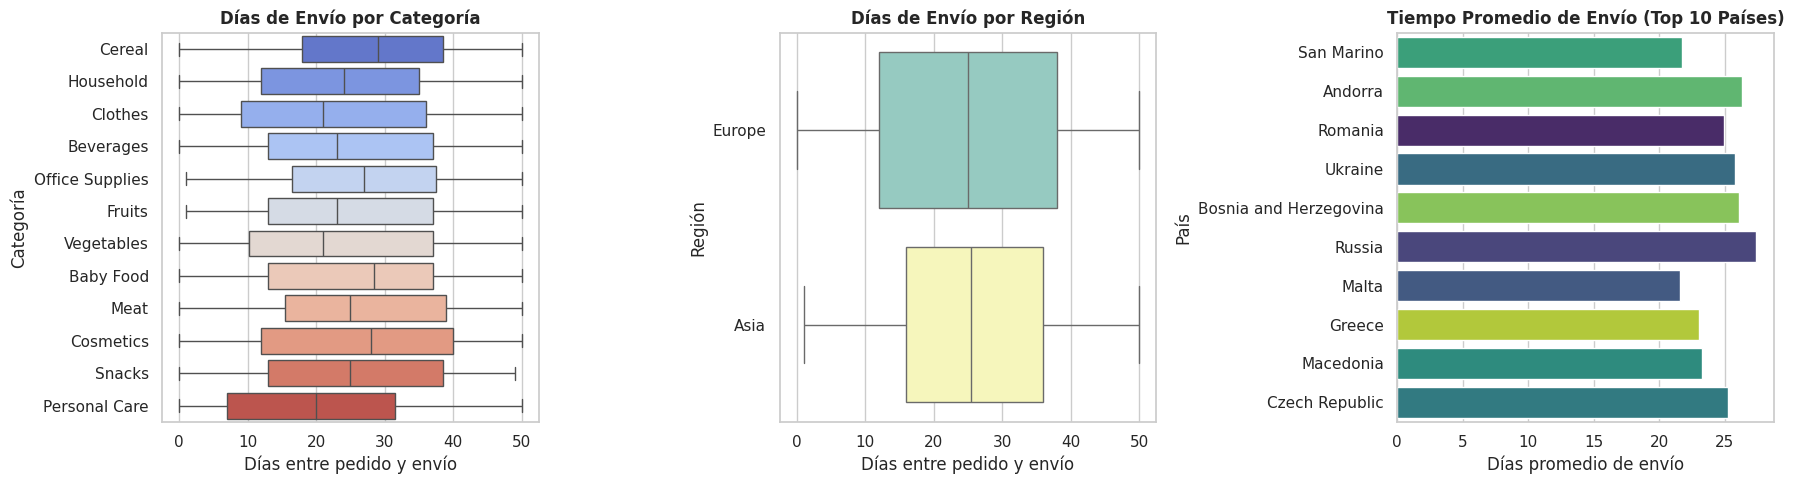

--- Top 10 Países por Volumen de Pedidos ---


,country,total_pedidos,unidades_vendidas,ingresos_usd,beneficio_usd,dias_envio_prom
1,Andorra,40,185686,47756693.17,15410036.63,26.275000
36,San Marino,40,192228,47883708.48,13792992.81,21.700000
34,Romania,34,166882,34286150.85,10793548.69,24.941176
6,Bosnia and Herzegovina,33,153545,50117508.49,13257602.77,26.060606
43,Ukraine,33,164577,53252317.54,14804925.74,25.757576
17,Greece,32,176859,38699541.70,12324450.13,23.000000
26,Macedonia,32,203078,49222085.25,13684099.95,23.218750
27,Malta,32,173641,47145320.81,14610127.88,21.562500
35,Russia,32,165954,46051659.81,13267682.64,27.375000
10,Czech Republic,31,142446,53543932.14,13635593.78,25.225806



--- Top 10 Países por Beneficio Neto (USD) ---


,country,total_pedidos,unidades_vendidas,ingresos_usd,beneficio_usd,dias_envio_prom
1,Andorra,40,185686,47756693.17,15410036.63,26.275000
43,Ukraine,33,164577,53252317.54,14804925.74,25.757576
27,Malta,32,173641,47145320.81,14610127.88,21.562500
36,San Marino,40,192228,47883708.48,13792992.81,21.700000
18,Hungary,25,152242,42408249.12,13786231.03,32.640000
26,Macedonia,32,203078,49222085.25,13684099.95,23.218750
10,Czech Republic,31,142446,53543932.14,13635593.78,25.225806
35,Russia,32,165954,46051659.81,13267682.64,27.375000
6,Bosnia and Herzegovina,33,153545,50117508.49,13257602.77,26.060606
17,Greece,32,176859,38699541.70,12324450.13,23.000000


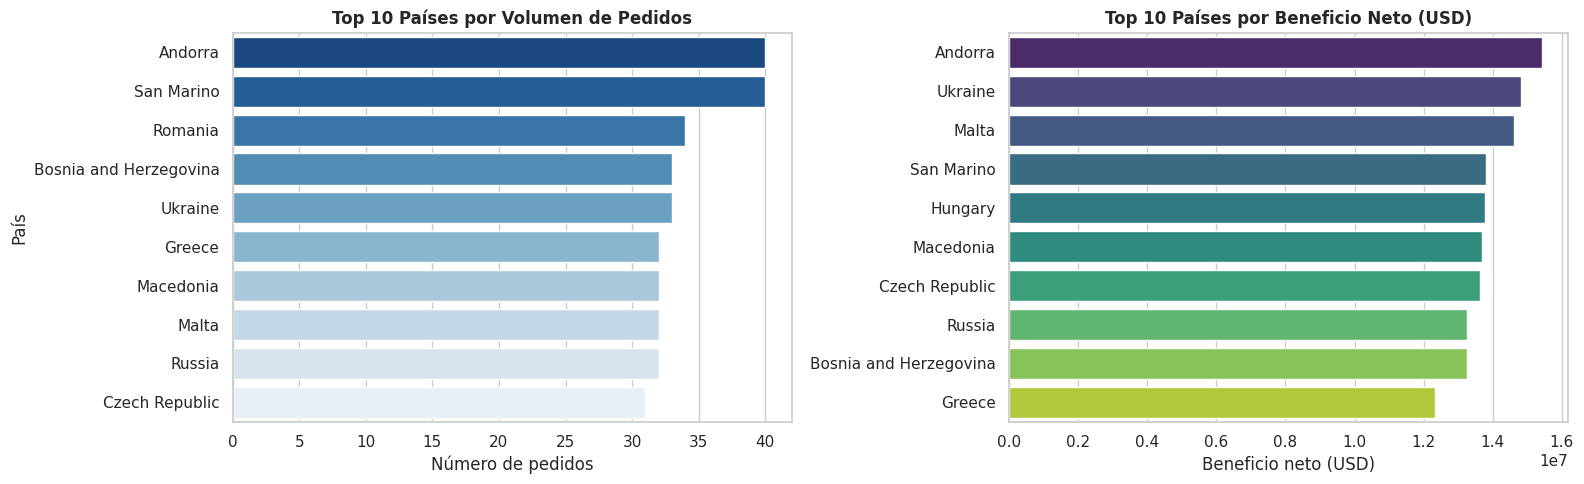


--- Resumen de dispersión de días de envío (df global, N = 1330 pedidos) ---


,count,mean,median,std,min,max
shipping_days,1330.0,24.78,25.0,14.58,0.0,50.0



--- Resumen de días de envío por categoría (media, mediana y desv. estándar) ---


,product_category,media,mediana,desv_est,min,max
0,Baby Food,26.34,28.5,14.28,0,50
1,Beverages,24.12,23.0,14.48,0,50
2,Cereal,27.18,29.0,13.72,0,50
3,Clothes,23.10,21.0,15.44,0,50
4,Cosmetics,25.91,28.0,15.46,0,50
5,Fruits,24.42,23.0,13.84,1,50
6,Household,23.94,24.0,13.71,0,50
7,Meat,25.85,25.0,14.72,0,50
8,Office Supplies,26.71,27.0,13.42,1,50
9,Personal Care,20.72,20.0,14.71,0,50


Nota analítica y de negocio: observar la dispersión (IQR y desviación estándar) por categoría y región complementa al promedio. Aunque el tiempo de envío tenga baja relación lineal directa con el beneficio registrado, en operación real la variabilidad logística puede afectar satisfacción, cancelaciones o recompra (aspectos no capturados en este dataset). Base: 1,330 pedidos con imputación por mediana en units_sold (frente a 1,328 pedidos sin vacíos en hojas de cálculo); df_geo excluye registros 'Unknown'.


In [19]:
# ==============================================================================
# 0. ASEGURAR df_geo (EXCLUYENDO REGISTROS SIN PAÍS / 'Unknown')
# ==============================================================================
if 'df_geo' not in locals():
    df_geo = df[(df['country'] != 'Unknown') & (df['region'] != 'Unknown')].copy()

# ==============================================================================
# 1. ANÁLISIS DE DÍAS DE ENVÍO (CATEGORÍA, REGIÓN Y TOP 10 PAÍSES POR PEDIDOS)
# ==============================================================================
top10_names = df_geo['country'].value_counts().head(10).index

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Por Categoría
sns.boxplot(
    data=df, x='shipping_days', y='product_category',
    hue='product_category', palette='coolwarm', legend=False, ax=axes[0]
)
axes[0].set_title('Días de Envío por Categoría', fontweight='bold')
axes[0].set_xlabel('Días entre pedido y envío')
axes[0].set_ylabel('Categoría')

# Por Región
sns.boxplot(
    data=df_geo, x='shipping_days', y='region',
    hue='region', palette='Set3', legend=False, ax=axes[1]
)
axes[1].set_title('Días de Envío por Región', fontweight='bold')
axes[1].set_xlabel('Días entre pedido y envío')
axes[1].set_ylabel('Región')

# Tiempo promedio de envío en el Top 10 de países por volumen de pedidos
sns.barplot(
    data=df_geo[df_geo['country'].isin(top10_names)],
    x='shipping_days',
    y='country',
    order=top10_names,
    errorbar=None,
    hue='country',
    palette='viridis',
    legend=False,
    ax=axes[2]
)
axes[2].set_title('Tiempo Promedio de Envío (Top 10 Países)', fontweight='bold')
axes[2].set_xlabel('Días promedio de envío')
axes[2].set_ylabel('País')

plt.tight_layout()
plt.show()

# ==============================================================================
# 2. TOP 10 PAÍSES POR VOLUMEN DE PEDIDOS Y POR BENEFICIO NETO
# ==============================================================================
resumen_paises = (
    df_geo.groupby('country', as_index=False)
    .agg(
        total_pedidos=('Order ID', 'nunique'),
        unidades_vendidas=('units_sold', 'sum'),
        ingresos_usd=('revenue', 'sum'),
        beneficio_usd=('profit', 'sum'),
        dias_envio_prom=('shipping_days', 'mean')
    )
)

top10_pedidos = resumen_paises.sort_values(by='total_pedidos', ascending=False).head(10)
top10_beneficio = resumen_paises.sort_values(by='beneficio_usd', ascending=False).head(10)

print("--- Top 10 Países por Volumen de Pedidos ---")
display(top10_pedidos)

print("\n--- Top 10 Países por Beneficio Neto (USD) ---")
display(top10_beneficio)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Top 10 por volumen de pedidos
sns.barplot(
    data=top10_pedidos,
    x='total_pedidos',
    y='country',
    order=top10_pedidos['country'],
    hue='country',
    palette='Blues_r',
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Top 10 Países por Volumen de Pedidos', fontweight='bold')
axes[0].set_xlabel('Número de pedidos')
axes[0].set_ylabel('País')

# Top 10 por beneficio neto
sns.barplot(
    data=top10_beneficio,
    x='beneficio_usd',
    y='country',
    order=top10_beneficio['country'],
    hue='country',
    palette='viridis',
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Top 10 Países por Beneficio Neto (USD)', fontweight='bold')
axes[1].set_xlabel('Beneficio neto (USD)')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

# ==============================================================================
# 3. MEJORA AÑADIDA: DISPERSIÓN DE ENVÍOS Y NOTA METODOLÓGICA / DE NEGOCIO
# ==============================================================================
print("\n--- Resumen de dispersión de días de envío (df global, N =", len(df), "pedidos) ---")
display(df['shipping_days'].agg(['count', 'mean', 'median', 'std', 'min', 'max']).to_frame().T.round(2))

print("\n--- Resumen de días de envío por categoría (media, mediana y desv. estándar) ---")
display(
    df.groupby('product_category', as_index=False)['shipping_days']
    .agg(media='mean', mediana='median', desv_est='std', min='min', max='max')
    .round(2)
)

print(
    "Nota analítica y de negocio: observar la dispersión (IQR y desviación estándar) por categoría y región "
    "complementa al promedio. Aunque el tiempo de envío tenga baja relación lineal directa con el beneficio "
    "registrado, en operación real la variabilidad logística puede afectar satisfacción, cancelaciones o "
    "recompra (aspectos no capturados en este dataset). Base: 1,330 pedidos con imputación por mediana en "
    "units_sold (frente a 1,328 pedidos sin vacíos en hojas de cálculo); df_geo excluye registros 'Unknown'."
)

Correlación de Pearson entre días de envío y beneficio: 0.0607
Contraste Pearson: r = 0.0607, p-valor = 0.0269


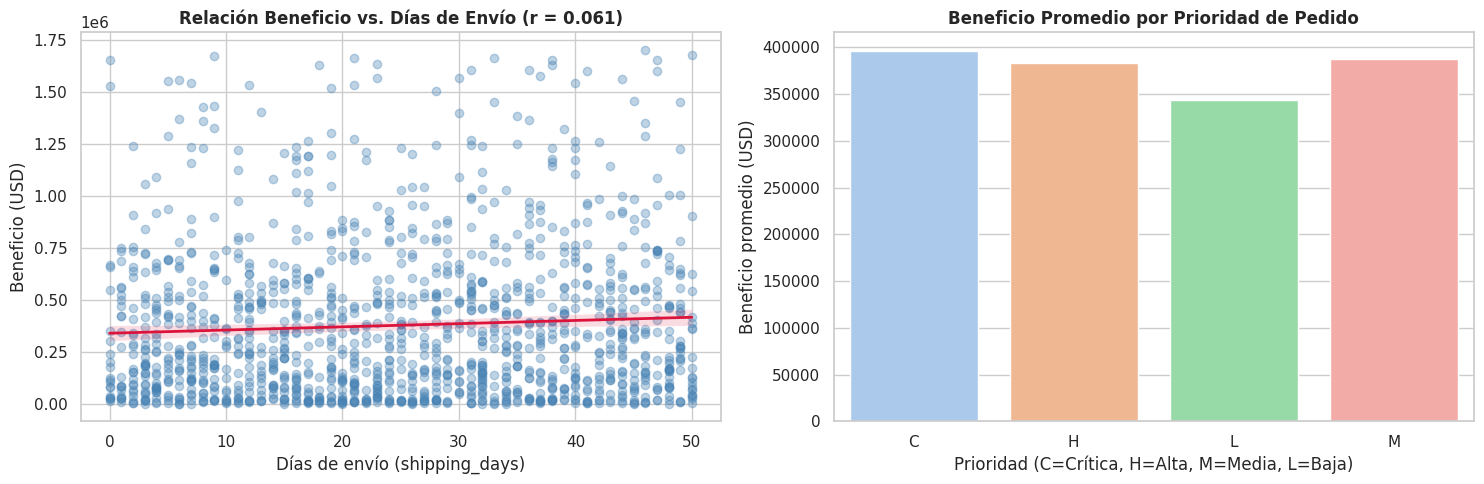


--- Resumen por Prioridad de Pedido (días de envío promedio y beneficio promedio) ---


,order_priority,dias_envio,beneficio_prom,pedidos
0,C,23.69,396028.31,307
1,H,24.32,383001.17,335
2,L,25.10,343937.39,334
3,M,25.84,387197.74,354



--- Beneficio promedio y correlación shipping_days vs profit por categoría ---


,product_category,r_pearson,dias_envio_prom,beneficio_prom
0,Baby Food,-0.0070,26.3393,481616.0461
1,Beverages,0.0855,24.1240,79352.5850
2,Cereal,0.0545,27.1845,400534.3121
3,Clothes,-0.0728,23.1048,413631.5657
4,Cosmetics,0.1216,25.9123,813362.3348
5,Fruits,-0.0895,24.4196,12731.5136
6,Household,-0.0321,23.9381,752190.3791
7,Meat,0.0292,25.8468,275809.1243
8,Office Supplies,0.1562,26.7073,633960.7825
9,Personal Care,-0.0424,20.7217,122548.1941


Lectura estadística y de negocio: una correlación lineal cercana a cero (r ~ 0.06) indica ausencia de relación lineal fuerte entre días de envío y beneficio, con alta dispersión vertical en profit. Conviene revisar diferencias por categoría o prioridad y tener presente que el tiempo de envío puede afectar factores no observados en este dataset —como satisfacción del cliente, cancelaciones o recompra—. Base analizada: 1,330 pedidos con imputación por mediana en units_sold (frente a 1,328 sin vacíos en hojas de cálculo).


In [20]:
correlacion = df['shipping_days'].corr(df['profit'])
print(f"Correlación de Pearson entre días de envío y beneficio: {correlacion:.4f}")

# Prueba de significancia lineal opcional (si scipy está disponible)
try:
    from scipy import stats
    r_stat, p_val = stats.pearsonr(df['shipping_days'].dropna(), df.loc[df['shipping_days'].notna(), 'profit'])
    print(f"Contraste Pearson: r = {r_stat:.4f}, p-valor = {p_val:.4f}")
except ImportError:
    pass

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Dispersión con línea de tendencia (conservado)
sns.regplot(
    data=df,
    x='shipping_days',
    y='profit',
    scatter_kws={'alpha': 0.35, 'color': 'steelblue'},
    line_kws={'color': 'crimson', 'linewidth': 2},
    ax=axes[0]
)
axes[0].set_title(f'Relación Beneficio vs. Días de Envío (r = {correlacion:.3f})', fontweight='bold')
axes[0].set_xlabel('Días de envío (shipping_days)')
axes[0].set_ylabel('Beneficio (USD)')

# Beneficio promedio por Prioridad de Pedido y tiempo de envío (conservado)
prio_summary = df.groupby('order_priority', as_index=False).agg(
    dias_envio=('shipping_days', 'mean'),
    beneficio_prom=('profit', 'mean'),
    pedidos=('Order ID', 'nunique')
)
sns.barplot(
    data=prio_summary,
    x='order_priority',
    y='beneficio_prom',
    hue='order_priority',
    palette='pastel',
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Beneficio Promedio por Prioridad de Pedido', fontweight='bold')
axes[1].set_xlabel('Prioridad (C=Crítica, H=Alta, M=Media, L=Baja)')
axes[1].set_ylabel('Beneficio promedio (USD)')

plt.tight_layout()
plt.show()

# Mejora añadida: tabla de prioridad e interpretación estadística / de negocio
print("\n--- Resumen por Prioridad de Pedido (días de envío promedio y beneficio promedio) ---")
display(prio_summary.round(2))

print("\n--- Beneficio promedio y correlación shipping_days vs profit por categoría ---")
cor_cat = (
    df.groupby('product_category', as_index=False)
    .apply(lambda g: pd.Series({
        'r_pearson': g['shipping_days'].corr(g['profit']),
        'dias_envio_prom': g['shipping_days'].mean(),
        'beneficio_prom': g['profit'].mean()
    }), include_groups=False)
)
display(cor_cat.round(4))

print(
    "Lectura estadística y de negocio: una correlación lineal cercana a cero (r ~ 0.06) indica ausencia "
    "de relación lineal fuerte entre días de envío y beneficio, con alta dispersión vertical en profit. "
    "Conviene revisar diferencias por categoría o prioridad y tener presente que el tiempo de envío puede "
    "afectar factores no observados en este dataset —como satisfacción del cliente, cancelaciones o recompra—. "
    "Base analizada: 1,330 pedidos con imputación por mediana en units_sold (frente a 1,328 sin vacíos en hojas de cálculo)."
)


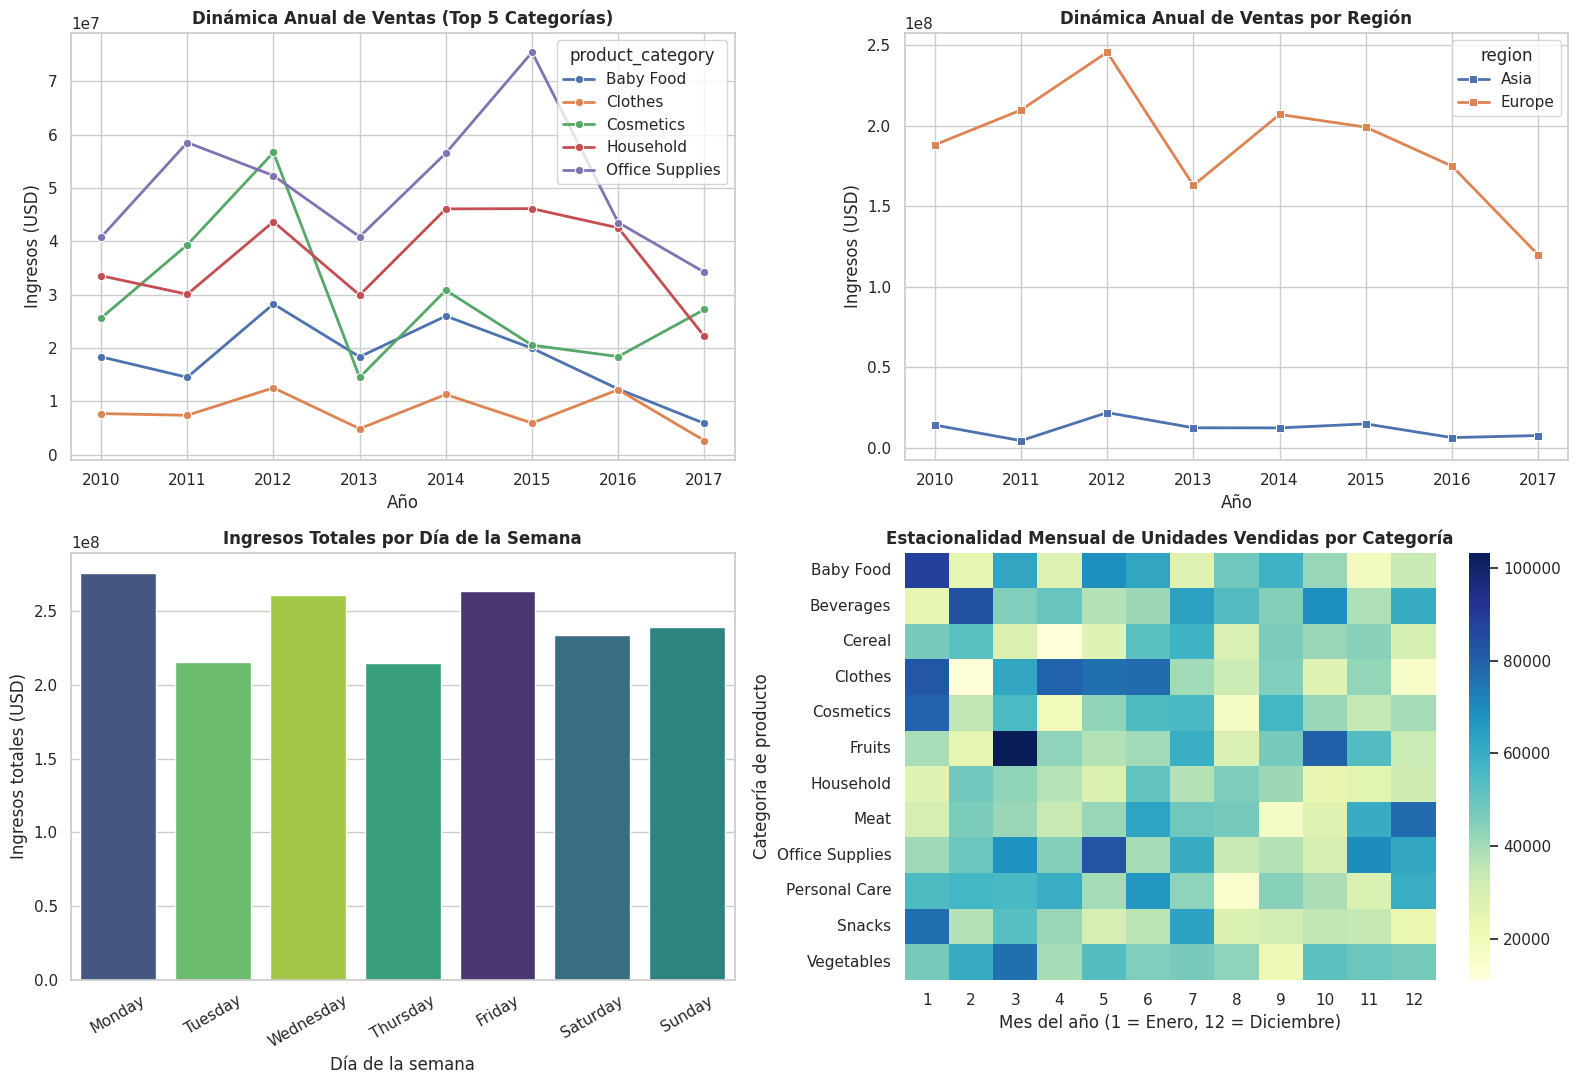


--- Ingresos Totales por Día de la Semana (USD) ---


,day_of_week,revenue
0,Monday,2.758521e+08
1,Tuesday,2.155675e+08
2,Wednesday,2.612157e+08
3,Thursday,2.149222e+08
4,Friday,2.638070e+08
5,Saturday,2.336411e+08
6,Sunday,2.395510e+08



--- Matriz de Estacionalidad Mensual: Unidades Vendidas por Categoría ---


order_month,1,2,3,4,5,6,7,8,9,10,11,12
product_category,,,,,,,,,,,,
Baby Food,88241,25381,62421,27516,68916,62530,27179,48518,57934,41933,18969,33168
Beverages,25044,83675,45403,50222,37113,41291,63724,54252,44783,68894,38307,60425
Cereal,47096,52382,28302,11069,26506,52494,57628,28471,46018,41911,43936,29872
Clothes,82227,11854,61721,78946,76110,77200,39904,32363,45571,26846,42669,15974
Cosmetics,79399,35359,55257,19837,42803,54836,55505,17545,56709,41504,34659,39878
Fruits,39041,25183,103302,43371,37558,40479,59665,28708,47750,79597,54065,32953
Household,26435,48054,42901,36853,28355,50987,37086,45941,41016,24395,26147,32079
Meat,30175,46317,41403,33977,41817,63135,48656,47782,17521,27025,60150,77266
Office Supplies,40839,49285,68193,44805,82505,39796,60214,33637,37286,29405,69743,61933


Contexto temporal y metodológico: el análisis anual y semanal cubre los 1,330 pedidos de df (con imputación por mediana en units_sold, frente a 1,328 sin vacíos en la versión de hojas de cálculo); el desglose regional utiliza df_geo (excluyendo registros sin país 'Unknown').


In [21]:
# Salvaguardas por si se ejecuta este bloque tras reiniciar o de forma parcial
if 'df_geo' not in locals():
    df_geo = df[(df['country'] != 'Unknown') & (df['region'] != 'Unknown')].copy()

if 'cat_summary' not in locals():
    cat_summary = (
        df.groupby('product_category', as_index=False)
        .agg(beneficio=('profit', 'sum'), ingresos=('revenue', 'sum'))
        .sort_values(by='beneficio', ascending=False)
        .reset_index(drop=True)
    )

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Evolución anual de ingresos por categoría (Top 5 categorías)
top5_cats = cat_summary['product_category'].head(5).tolist()
dinamica_cat = (
    df[df['product_category'].isin(top5_cats)]
    .groupby(['order_year', 'product_category'], as_index=False)['revenue']
    .sum()
)
sns.lineplot(data=dinamica_cat, x='order_year', y='revenue', hue='product_category', marker='o', linewidth=2, ax=axes[0, 0])
axes[0, 0].set_title('Dinámica Anual de Ventas (Top 5 Categorías)', fontweight='bold')
axes[0, 0].set_xlabel('Año')
axes[0, 0].set_ylabel('Ingresos (USD)')

# 2. Evolución anual de ingresos por Región
dinamica_reg = df_geo.groupby(['order_year', 'region'], as_index=False)['revenue'].sum()
sns.lineplot(data=dinamica_reg, x='order_year', y='revenue', hue='region', marker='s', linewidth=2, ax=axes[0, 1])
axes[0, 1].set_title('Dinámica Anual de Ventas por Región', fontweight='bold')
axes[0, 1].set_xlabel('Año')
axes[0, 1].set_ylabel('Ingresos (USD)')

# 3. Ventas por día de la semana usando day_name()
orden_dias = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
ventas_dia = df.groupby('day_of_week', as_index=False)['revenue'].sum()
sns.barplot(data=ventas_dia, x='day_of_week', y='revenue', order=orden_dias, hue='day_of_week', palette='viridis', legend=False, ax=axes[1, 0])
axes[1, 0].set_title('Ingresos Totales por Día de la Semana', fontweight='bold')
axes[1, 0].set_xlabel('Día de la semana')
axes[1, 0].set_ylabel('Ingresos totales (USD)')
axes[1, 0].tick_params(axis='x', rotation=30)

# 4. Mapa de calor de estacionalidad: Mes vs Categoría de producto
pivot_estacional = df.pivot_table(index='product_category', columns='order_month', values='units_sold', aggfunc='sum')
sns.heatmap(pivot_estacional, cmap='YlGnBu', annot=False, ax=axes[1, 1])
axes[1, 1].set_title('Estacionalidad Mensual de Unidades Vendidas por Categoría', fontweight='bold')
axes[1, 1].set_xlabel('Mes del año (1 = Enero, 12 = Diciembre)')
axes[1, 1].set_ylabel('Categoría de producto')

plt.tight_layout()
plt.show()

# Mejoras añadidas (sin alterar los 4 gráficos anteriores)
ventas_dia_ordenado = ventas_dia.set_index('day_of_week').reindex(orden_dias).reset_index()
print("\n--- Ingresos Totales por Día de la Semana (USD) ---")
display(ventas_dia_ordenado.round(2))

print("\n--- Matriz de Estacionalidad Mensual: Unidades Vendidas por Categoría ---")
display(pivot_estacional.fillna(0).astype(int))

print(
    "Contexto temporal y metodológico: el análisis anual y semanal cubre los 1,330 pedidos de df "
    "(con imputación por mediana en units_sold, frente a 1,328 sin vacíos en la versión de hojas de cálculo); "
    "el desglose regional utiliza df_geo (excluyendo registros sin país 'Unknown')."
)

In [22]:
# Salvaguarda por si se ejecuta este bloque tras reiniciar o de forma parcial
if 'df_geo' not in locals():
    df_geo = df[(df['country'] != 'Unknown') & (df['region'] != 'Unknown')].copy()

# Verificación rápida de cifras exactas por región, canal y día de la semana para el informe final
print("--- Beneficio por Región ---")
print(df_geo.groupby('region')['profit'].agg(['count', 'sum', 'mean']))

print("\n--- Desempeño por Canal de Venta ---")
print(df.groupby('sales_channel')[['revenue', 'profit']].agg(['count', 'sum', 'mean']))

print("\n--- Top 5 Países por Beneficio ---")
print(df_geo.groupby('country')['profit'].sum().sort_values(ascending=False).head(5))

print("\n--- Ingresos por Día de la Semana ---")
print(df.groupby('day_of_week')['revenue'].agg(['count', 'sum', 'mean']).sort_values(by='sum', ascending=False))

# Mejora añadida: control de cuadre global y nota metodológica
print("\n--- Cuadre Global de Control (df completo) ---")
print(f"Pedidos totales: {len(df):,} | Pedidos con país conocido (df_geo): {len(df_geo):,}")
print(f"Ingresos totales: ${df['revenue'].sum():,.2f} | Beneficio total: ${df['profit'].sum():,.2f}")
print(
    "Nota de trazabilidad: df conserva los 1,330 pedidos mediante imputación por mediana en units_sold "
    "(frente a 1,328 registros en la depuración sin vacíos de hojas de cálculo)."
)

--- Beneficio por Región ---
        count           sum           mean
region                                    
Asia       82  2.515225e+07  306734.792073
Europe   1166  4.489515e+08  385035.583662

--- Desempeño por Canal de Venta ---
              revenue                             profit                \
                count           sum          mean  count           sum   
sales_channel                                                            
Offline           667  8.741879e+08  1.310627e+06    667  2.538612e+08   
Online            663  8.303688e+08  1.252442e+06    663  2.479679e+08   

                              
                        mean  
sales_channel                 
Offline        380601.540105  
Online         374008.959563  

--- Top 5 Países por Beneficio ---
country
Andorra       15410036.63
Ukraine       14804925.74
Malta         14610127.88
San Marino    13792992.81
Hungary       13786231.03
Name: profit, dtype: float64

--- Ingresos por Día de la Sema

## Etapa 4: Informe Ejecutivo y Conclusiones de Negocio (Dataset Simulado)

> **Alcance del informe:** Las cifras y conclusiones de esta sección se derivan de un **conjunto de datos ficticio / de curso** (1,330 transacciones procesadas en Python) y se presentan con fines demostrativos de análisis de datos y metodología, no como desempeño financiero real.

### 1. Resumen de Calidad e Integridad de Datos

* **Consolidación relacional:**
  Se integraron 1,330 transacciones (`events.csv`) con el catálogo de productos (`products.csv` mediante `Product ID = id`) y la base geográfica de territorios (`countries.csv` mediante `Country Code = alpha-3`), aplicando cruce izquierdo (`left join`) para preservar el volumen completo de registros del ejercicio.
* **Tratamiento de valores faltantes y casos críticos:**
  * **Códigos geográficos ausentes (`Unknown`):** Se identificaron 82 registros (6.17 %) sin `Country Code` en `events.csv`. Para no alterar los totales consolidados ni asignar ubicaciones arbitrarias, se etiquetaron como `Unknown` en las métricas globales y se excluyeron únicamente de las agregaciones geográficas (`df_geo`).
  * **Imputación de `Units Sold`:** Se imputaron 2 registros (0.15 %) faltantes en `Units Sold` utilizando la mediana de unidades vendidas de su mismo `Product ID` (redondeada a entero), conservando los 1,330 pedidos en Python (frente a los 1,328 pedidos de la depuración sin vacíos en la versión de hojas de cálculo).
  * **Código ISO de Namibia (`NA`):** Mediante `keep_default_na=False` y verificación explícita, se evitó que el código ISO alpha-2 `'NA'` de Namibia se interpretara como valor nulo.
* **Estandarización, duplicados y anomalías:**
  Se normalizaron inconsistencias de texto y espacios en las variables categóricas (incluyendo `'online'` a `'Online'` en `Sales Channel`), se neutralizaron caracteres homógrafos cirílicos visuales mediante mapeo a caracteres latinos y se verificó la integridad de claves y fechas (`0` duplicados exactos tras normalización y `shipping_days` entre 0 y 50 días, sin fechas de envío anteriores al pedido ni costos unitarios superiores al precio unitario).

---

### 2. Desempeño Financiero y Comercial Global (Datos del Ejercicio)

* **Volumen y alcance:**
  El *dataset* consolidado abarca 1,330 pedidos y 6,586,061 unidades vendidas, con cobertura de 45 países en `df_geo` y presencia concentrada en Europa y Asia.
* **Rentabilidad:**
  En el conjunto simulado se registran ingresos totales por `\$1,704,556,262.10 USD` frente a costos operativos de `\$1,202,727,151.86 USD`, lo que arroja un beneficio neto de `\$501,829,110.24 USD` (un margen neto global del **29.44 %**) y un ingreso promedio por pedido de `\$1,281,621.25 USD`.

---

### 3. Hallazgos Clave por Dimensión de Negocio

#### A. Portafolio de Productos: Volumen, Margen y Pareto / ABC
* **Líderes en beneficio y concentración (Pareto / ABC):**
  **Cosmetics** encabeza el beneficio neto con `\$92.72 millones USD` (114 pedidos), seguida por **Office Supplies** (`\$77.98 millones USD`) y **Household** (`\$72.96 millones USD`). Estas tres categorías concentran cerca del **48.6 %** del beneficio neto total, conformando el núcleo de mayor peso en la clasificación Pareto / ABC.
* **Paradoja de volumen frente a margen:**
  **Office Supplies** (617,641 unidades) y **Beverages** (613,133 unidades) destacan por su alto volumen de unidades, pero **Beverages** aporta `\$9.60 millones USD` de beneficio y **Fruits** (591,672 unidades) aporta `\$1.43 millones USD` debido a su menor precio y margen unitario. En contraste, **Clothes** alcanza un margen porcentual elevado (`\$43.43 millones USD` de beneficio sobre `\$64.63 millones USD` de ingresos, equivalente a **67.2 %** de margen).

#### B. Geografía y Canales de Venta
* **Distribución geográfica:**
  Entre los países identificados en `df_geo` (45 países), **Europa** concentra una presencia destacada tanto en número de mercados activos como en beneficio y volumen acumulado, mientras que los rankings por cantidad de pedidos y por beneficio neto muestran matices según el mix de productos de cada país.
* **Equilibrio entre canales:**
  Los canales **Offline** (667 pedidos) y **Online** (663 pedidos tras estandarización) presentan una distribución prácticamente equilibrada (**50.2 %** frente a **49.8 %**), lo que evidencia el peso conjunto de ambos canales en la generación de ingresos y beneficio dentro del *dataset*.

#### C. Eficiencia Logística y Relación con el Beneficio
* **Tiempos de entrega y dispersión:**
  El tiempo de envío presenta un promedio de **24.78 días** y una mediana de **25 días**, con un rango de **0 a 50 días** y dispersión visible en las distribuciones por categoría, región y prioridad.
* **Correlación lineal y lectura operativa:**
  La correlación lineal de Pearson entre `shipping_days` y `profit` es baja (**r = 0.0607**), lo que indica que el beneficio por pedido responde principalmente al tipo de producto, su margen y las unidades vendidas más que a una relación lineal con los días de envío. No obstante, la variabilidad logística y los tiempos de despacho sí pueden incidir en factores operativos no registrados en este *dataset* —como satisfacción del cliente, cancelaciones, devoluciones o recompra—.

#### D. Dinámica Temporal y Estacionalidad
* **Patrón anual, semanal y mensual:**
  Las series anuales muestran la evolución de ingresos en las principales categorías y regiones a lo largo del periodo; las ventas por día de la semana mantienen actividad en los siete días con diferencias moderadas entre jornadas, y el mapa de calor mensual evidencia picos estacionales diferenciados según la categoría de producto.

---

### 4. Recomendaciones Analíticas y Limitaciones del Dataset

1. **Priorizar el análisis del mix de alto margen y la venta cruzada:**
   Como criterio analítico sobre estos datos, conviene enfocar la revisión de rentabilidad y surtido en líneas de alto aporte o margen (como **Cosmetics**, **Household** y **Clothes**), evaluando cómo interactúan con categorías de alta rotación (**Beverages** y **Office Supplies**) en estrategias de volumen o *cross-selling*.
2. **Aplicar reglas de validación de datos desde el origen:**
   Como buena práctica de ingeniería de datos, se recomienda exigir `Country Code` válido al registrar operaciones —evitando el 6.17 % de registros sin geografía— y restringir `Sales Channel` a un catálogo cerrado desde la entrada de datos.
3. **Contrastan tiempos de despacho con prioridades y variables operativas ausentes:**
   Dado que el tiempo medio de envío ronda los ~25 días entre distintas prioridades (`C`, `H`, `M`, `L`), un análisis posterior debería revisar acuerdos logísticos por urgencia e incorporar variables operativas no presentes en este *dataset* ficticio (costos de envío detallados, devoluciones, cancelaciones, satisfacción y recurrencia de compra).